In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [78]:
data = pd.read_csv("Apistox.csv")

print("Original dataset shape:", data.shape)
display(data.head())

Original dataset shape: (1035, 13)


,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1


In [79]:
df = pd.DataFrame(data)

In [80]:
df

,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1030,Benzyl 4-amino-3-chloro-6-(4-chloro-2-fluoro-3...,70495450,1390661-72-9,COc1c(Cl)ccc(-c2nc(C(=O)OCc3ccccc3)c(Cl)c(N)c2...,ECOTOX,2023,Contact,1,0,0,0,0,1
1031,Glyphosate-dimethylammonium,13208144,34494-04-7,CNC.O=C(O)CNCP(=O)(O)O,PPDB,2023,Contact,1,0,0,0,0,1
1032,Glyphosate-monoammonium,11615303,114370-14-8,N.O=C(O)CNCP(=O)(O)O,PPDB,2023,Contact,1,0,0,0,0,1
1033,Bixlozone (Ref: F9600),15056663,81777-95-9,CC1(C)CON(Cc2ccc(Cl)cc2Cl)C1=O,PPDB,2023,Contact,1,0,0,0,0,1


In [81]:

print("Dataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe().T)

print("\nTarget distribution:")
display(df["label"].value_counts(dropna=False))

print("\nTarget distribution (%):")
display(
    (df["label"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nSource distribution:")
display(df["source"].value_counts())

print("\nToxicity type distribution:")
display(df["toxicity_type"].value_counts())

print("\nPPDB level distribution:")
display(df["ppdb_level"].value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1035 entries, 0 to 1034
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   name                1035 non-null   object
 1   CID                 1035 non-null   int64 
 2   CAS                 1035 non-null   object
 3   SMILES              1035 non-null   object
 4   source              1035 non-null   object
 5   year                1035 non-null   int64 
 6   toxicity_type       1035 non-null   object
 7   herbicide           1035 non-null   int64 
 8   fungicide           1035 non-null   int64 
 9   insecticide         1035 non-null   int64 
 10  other_agrochemical  1035 non-null   int64 
 11  label               1035 non-null   int64 
 12  ppdb_level          1035 non-null   int64 
dtypes: int64(8), object(5)
memory usage: 105.2+ KB

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
CID,1035.0,6.619015e+06,1.795840e+07,234.0,18449.5,86132.0,5363382.0,163360625.0
year,1035.0,1.969225e+03,3.941811e+01,1832.0,1958.0,1977.0,1995.0,2023.0
herbicide,1035.0,3.420290e-01,4.746186e-01,0.0,0.0,0.0,1.0,1.0
fungicide,1035.0,1.903382e-01,3.927577e-01,0.0,0.0,0.0,0.0,1.0
insecticide,1035.0,2.193237e-01,4.139884e-01,0.0,0.0,0.0,0.0,1.0
other_agrochemical,1035.0,2.086957e-01,4.065729e-01,0.0,0.0,0.0,0.0,1.0
label,1035.0,2.859903e-01,4.521033e-01,0.0,0.0,0.0,1.0,1.0
ppdb_level,1035.0,9.942029e-01,5.801064e-01,0.0,1.0,1.0,1.0,2.0



Target distribution:


label
0    739
1    296
Name: count, dtype: int64


Target distribution (%):


label
0    71.4
1    28.6
Name: proportion, dtype: float64

... (2 outputs left out)


Toxicity type distribution:


toxicity_type
Contact    625
Oral       291
Other      119
Name: count, dtype: int64


PPDB level distribution:


ppdb_level
1    687
0    177
2    171
Name: count, dtype: int64

In [82]:
print("Missing values before treatment:")
display(df.isnull().sum().sort_values(ascending=False))

# The target cannot be imputed meaningfully for supervised learning.
df = df.dropna(subset=["label"]).copy()

# Fill missing numerical values with each column's median.
numeric_columns = df.select_dtypes(include="number").columns

for column in numeric_columns:
    if column != "label":
        df[column] = df[column].fillna(df[column].median())

# Fill missing categorical values with mode.
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

print("\nMissing values after treatment:")
display(df.isnull().sum().sort_values(ascending=False))


Missing values before treatment:


name                  0
CID                   0
CAS                   0
SMILES                0
source                0
year                  0
toxicity_type         0
herbicide             0
fungicide             0
insecticide           0
other_agrochemical    0
label                 0
ppdb_level            0
dtype: int64


Missing values after treatment:


name                  0
CID                   0
CAS                   0
SMILES                0
source                0
year                  0
toxicity_type         0
herbicide             0
fungicide             0
insecticide           0
other_agrochemical    0
label                 0
ppdb_level            0
dtype: int64

In [83]:

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)


Number of duplicate rows: 0
Dataset shape after removing duplicates: (1035, 13)


<Axes: >

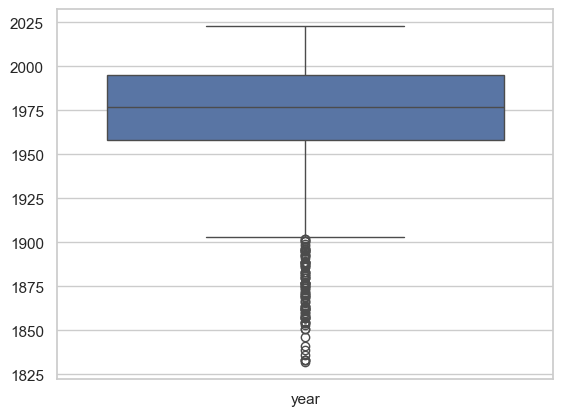

In [84]:
sns.boxplot(data=df[["year"]])

In [85]:
def cap_outliers_iqr(dataframe, exclude_columns=None):

    dataframe = dataframe.copy()

    if exclude_columns is None:
        exclude_columns = []

    numeric_columns = dataframe.select_dtypes(include="number").columns

    for column in numeric_columns:
        if column in exclude_columns:
            continue

        q1 = dataframe[column].quantile(0.25)
        q3 = dataframe[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        dataframe[column] = dataframe[column].clip(
            lower=lower_bound,
            upper=upper_bound
        )

    return dataframe


df = cap_outliers_iqr(
    df,
    exclude_columns=[
        "CID",
        "label",
        "herbicide",
        "fungicide",
        "insecticide",
        "other_agrochemical",
        "ppdb_level"
    ]
)

print("Outlier capping completed.")

Outlier capping completed.


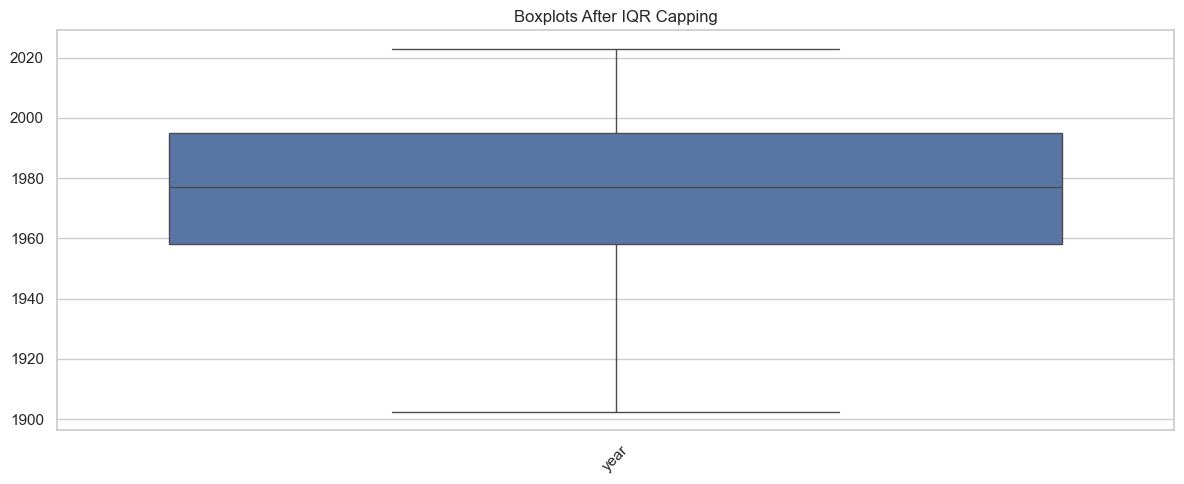

In [86]:
boxplot_columns = [
    column for column in ["year"]
    if column in df.columns
]

plt.figure(figsize=(12, 5))
sns.boxplot(data=df[boxplot_columns])

plt.title("Boxplots After IQR Capping")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [87]:
target_column = "label"

# Categorical columns in this dataset.
categorical_columns = [
    column for column in ["source", "toxicity_type"]
    if column in df.columns
]

print("Categorical predictor columns:", categorical_columns)


Categorical predictor columns: ['source', 'toxicity_type']


In [88]:
# CID is an identifier, so it is excluded from the predictors.

X = df.drop(
    columns=[target_column, "CID"],
    errors="ignore"
)

y = df[target_column].astype(int)

print("Independent variables (X):", X.shape)
print("Dependent variable (y):", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Independent variables (X): (1035, 11)
Dependent variable (y): (1035,)

Target classes:
label
0    739
1    296
Name: count, dtype: int64


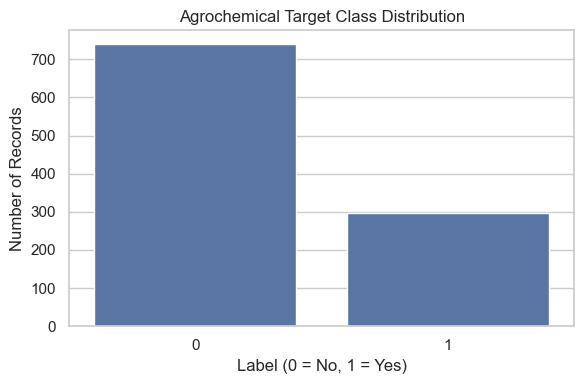

In [89]:
# Visualization 1: Target class distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="label")

plt.title("Agrochemical Target Class Distribution")
plt.xlabel("Label (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

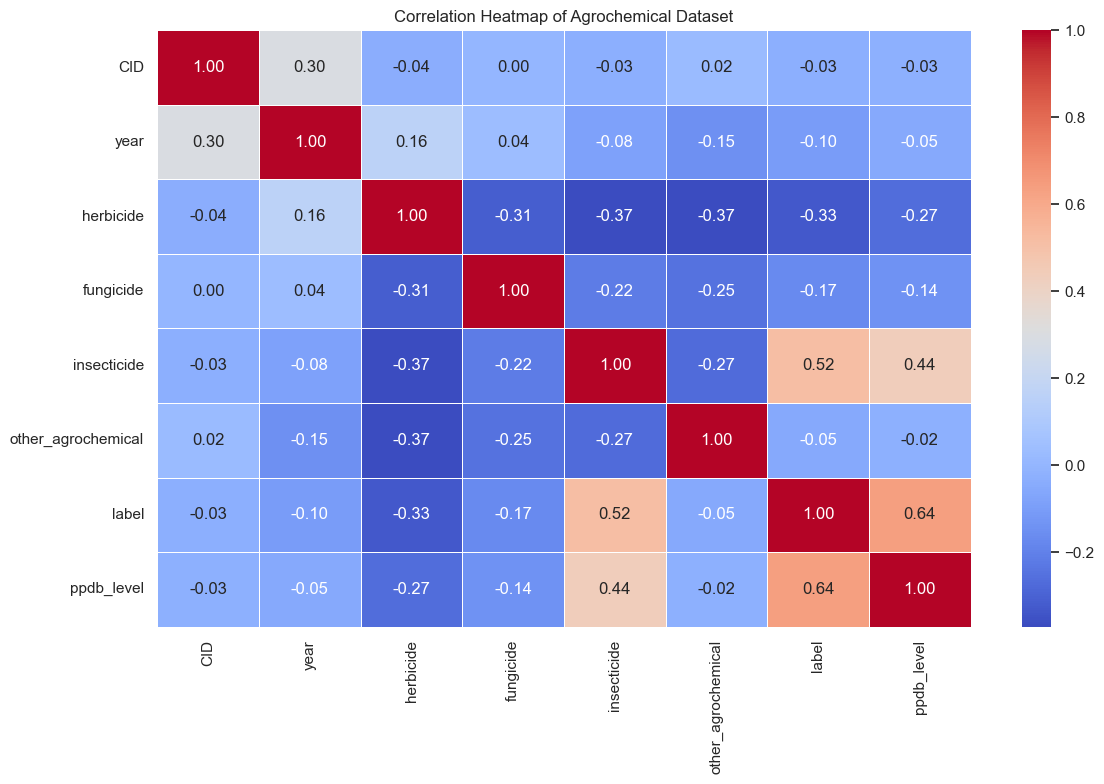

In [90]:
# Select numerical columns
numeric_data = df.select_dtypes(include="number")

# Calculate correlation
correlation = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Agrochemical Dataset")
plt.tight_layout()
plt.show()

In [91]:
numeric_data = df.drop(columns=["CID"], errors="ignore").select_dtypes(include="number")

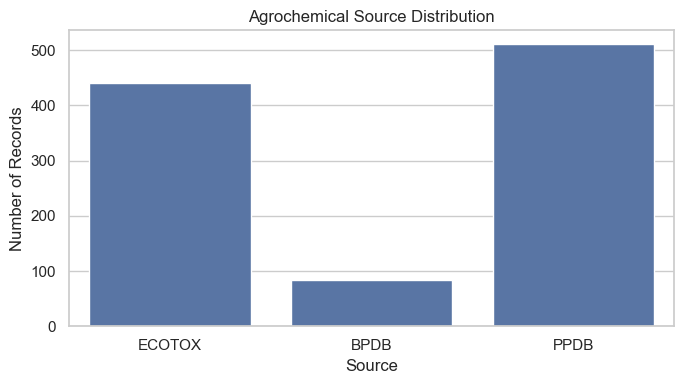

In [92]:
# Visualization 3: Agrochemical source distribution
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="source")

plt.title("Agrochemical Source Distribution")
plt.xlabel("Source")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [93]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (828, 11)
Testing features: (207, 11)

Training target distribution:
label
0    0.714
1    0.286
Name: proportion, dtype: float64

Testing target distribution:
label
0    0.715
1    0.285
Name: proportion, dtype: float64


In [94]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

categorical_features = [
    column for column in categorical_columns
    if column in X_train.columns
]

# Remove categorical columns from the numerical feature list.
numeric_features = [
    column for column in numeric_features
    if column not in categorical_features
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['year', 'herbicide', 'fungicide', 'insecticide', 'other_agrochemical', 'ppdb_level']
Categorical features: ['source', 'toxicity_type']


In [95]:
selector = SelectKBest(score_func=f_classif, k=10)

X_train_new = selector.fit_transform(X_train_processed, y_train)

X_test_new = selector.transform(X_test_processed)

In [96]:
selected_features = feature_names[selector.get_support()]

print("Selected Features:")
print(selected_features)

Selected Features:
['numeric__year' 'numeric__herbicide' 'numeric__fungicide'
 'numeric__insecticide' 'numeric__other_agrochemical'
 'numeric__ppdb_level' 'categorical__source_BPDB'
 'categorical__source_ECOTOX' 'categorical__source_PPDB'
 'categorical__toxicity_type_Contact']


In [97]:
feature_scores = pd.DataFrame({
    'Feature': feature_names,
    'Score': selector.scores_,
    'Selected': selector.get_support()
})

feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

print(feature_scores)

                               Feature       Score  Selected
5                  numeric__ppdb_level  557.305733      True
3                 numeric__insecticide  318.975198      True
1                   numeric__herbicide  110.374169      True
2                   numeric__fungicide   22.330749      True
7           categorical__source_ECOTOX   15.671699      True
0                        numeric__year   12.832600      True
8             categorical__source_PPDB    9.337802      True
6             categorical__source_BPDB    2.342052      True
4          numeric__other_agrochemical    1.921725      True
9   categorical__toxicity_type_Contact    1.204841      True
10     categorical__toxicity_type_Oral    0.584838     False
11    categorical__toxicity_type_Other    0.366029     False


In [98]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

In [99]:
# Store results
scores = []

for name, model in models.items():

    model.fit(X_train_new, y_train)

    y_pred = model.predict(X_test_new)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)

    scores.append({
        "Model": name,
        "Accuracy": round(accuracy, 2),
        "Precision": round(precision, 2),
        "F1": round(f1, 2),
        "Recall": round(recall, 2)
    })

# Convert to DataFrame for display
results_df = pd.DataFrame(scores)

print(results_df)

                 Model  Accuracy  Precision    F1  Recall
0  Logistic Regression      0.87       0.83  0.75    0.68
1        Decision Tree      0.86       0.80  0.73    0.68
2        Random Forest      0.88       0.86  0.78    0.71
